# Unit 3 — Multimedia and Interactive Visualization (UE24CS342AA9)
## Activity Notebook: The Fraud-Ops War Room

### Scenario

You've joined the **Fraud Operations** team at **PayKart**, a card-payments company. Last month's numbers looked wrong and
the Head of Fraud Ops has called a review. You have 30 days of transactions with the automated detector's score and the
investigators' confirmed labels (`unit3_ppt7_card_transactions.csv`). Their requests:

1. *"I don't want a list of alerts. Show me the whole month first — is anything unusual going on?"*
2. *"The investigators keep saying 'night-time, far-from-home' transactions are risky. Show me, across ALL our views at
   once, what those transactions look like."*
3. *"Engineering wants to build the interactive filter tool on our full history: 50 million transactions. Will a slider
   still feel instant?"*
4. *"The detector threshold is 0.5 and the team is drowning in alerts. We can review at most **150 alerts a month**. Where
   should the threshold be?"*
5. *"Give the investigators a tool where they can poke at the flagged cases themselves."*
6. *"Someone says it was a fraud ring in one city. Prove it — or kill the idea."*

Cells marked **`# TODO`** are for you to complete. Markdown cells marked **Reflection** are for you to answer in your own
words. Interactive (plotly) figures support zoom, pan, hover, selection and clicking.

## Part 0 — Setup (given)

Run this cell as-is. It loads `tx` and adds `night` (hour < 6) and a readable `label` column.

In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import plotly.express as px
import plotly.graph_objects as go

np.random.seed(0)
plt.rcParams["axes.spines.top"] = False
plt.rcParams["axes.spines.right"] = False
# If plotly figures come out blank: classic Jupyter -> pio.renderers.default = "notebook";
# Google Colab -> "colab"; VS Code / JupyterLab work out of the box.
import plotly.io as pio

tx = pd.read_csv("/content/unit3_ppt7_card_transactions.csv", parse_dates=["timestamp"])
tx["night"] = tx.hour < 6
tx["label"] = np.where(tx.is_fraud == 1, "confirmed fraud", "legitimate")

print(f"{len(tx):,} transactions | {tx.is_fraud.sum()} confirmed fraud | days {tx.day.min()}-{tx.day.max()}")
tx.head()

5,520 transactions | 120 confirmed fraud | days 1-30


,txn_id,timestamp,day,hour,customer_id,city,merchant_category,amount_inr,distance_from_home_km,detector_score,is_fraud,night,label
0,T00001,2026-06-01 02:39:00,1,2,C0618,Chennai,Groceries,1666.0,5.2,0.2050,0,True,legitimate
1,T00002,2026-06-01 02:58:00,1,2,C0769,Bengaluru,Travel,11733.0,4.7,0.2322,0,True,legitimate
2,T00003,2026-06-01 02:46:00,1,2,C0104,Delhi,Electronics,22342.0,1026.0,0.9932,0,True,legitimate
3,T00004,2026-06-01 03:11:00,1,3,C0824,Bengaluru,Restaurants,2497.0,0.8,0.0775,0,True,legitimate
4,T00005,2026-06-01 04:30:00,1,4,C1588,Bengaluru,Gift Cards,1447.0,0.4,0.0681,0,True,legitimate


## Task 1 — Overview First (Request #1)

**Real-world usage:** Fraud dashboards start from a whole-period overview before any alert list.

**Why this technique:** Shneiderman's mantra — **overview first**, then zoom and filter, then details (Slide 30); a
**reordered** matrix makes patterns pop out (Slide 39).

**TODO:**
1. Plot daily transaction counts with daily confirmed fraud on a second axis.
2. Build a city × day matrix of confirmed-fraud **counts**, reorder rows and columns by their totals, and show it as a
   heatmap with labelled axes.
3. Print the (city, day) cells with the most fraud.

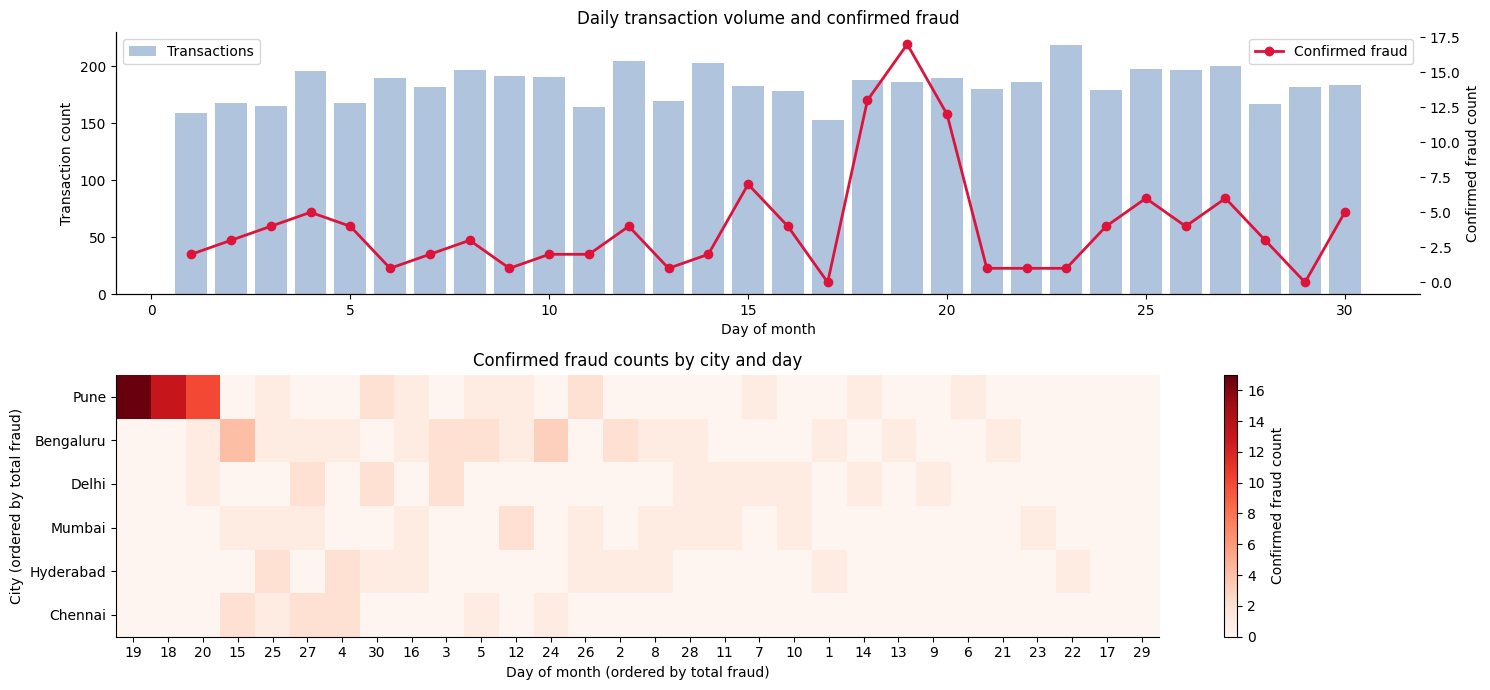

Top city-day cells by confirmed fraud:
city       day
Pune       19     17
           18     13
           20     10
Bengaluru  15      4
           24      3
           3       2
Pune       26      2
Bengaluru  2       2
           5       2
Pune       30      2


In [2]:
fig, axes = plt.subplots(2, 1, figsize=(15, 7))

# TODO 1: Daily volume and confirmed fraud on a secondary axis.
daily = tx.groupby("day").agg(
    transactions=("txn_id", "size"),
    fraud=("is_fraud", "sum")
)
axes[0].bar(daily.index, daily["transactions"], color="lightsteelblue", label="Transactions")
axes[0].set_ylabel("Transaction count")
axes[0].set_xlabel("Day of month")
axes[0].set_title("Daily transaction volume and confirmed fraud")
ax2 = axes[0].twinx()
ax2.plot(daily.index, daily["fraud"], color="crimson", marker="o", linewidth=2, label="Confirmed fraud")
ax2.set_ylabel("Confirmed fraud count")
axes[0].legend(loc="upper left")
ax2.legend(loc="upper right")

# TODO 2: City x day fraud-count matrix, ordered by marginal totals.
heat = tx.pivot_table(index="city", columns="day", values="is_fraud",
                      aggfunc="sum", fill_value=0)
heat = heat.loc[heat.sum(axis=1).sort_values(ascending=False).index,
                heat.sum(axis=0).sort_values(ascending=False).index]
im = axes[1].imshow(heat, aspect="auto", cmap="Reds")
axes[1].set_yticks(range(len(heat.index)), labels=heat.index)
axes[1].set_xticks(range(len(heat.columns)), labels=heat.columns)
axes[1].set_xlabel("Day of month (ordered by total fraud)")
axes[1].set_ylabel("City (ordered by total fraud)")
axes[1].set_title("Confirmed fraud counts by city and day")
fig.colorbar(im, ax=axes[1], label="Confirmed fraud count")

plt.tight_layout(); plt.show()

# TODO 3: Highest-fraud city-day cells.
top_cells = heat.stack().sort_values(ascending=False).head(10)
print("Top city-day cells by confirmed fraud:")
print(top_cells.to_string())


**Your answer:** The overview shows the *when* and *where* of fraud, not just which individual transactions received high detector scores. In particular, Pune has a concentrated spike on days 18–20, with the largest cell on day 19 (17 confirmed cases). A score-sorted alert list would not make this city-by-day concentration or the broader daily volume pattern easy to see. The lecture concept is **overview first** and the **reordered matrix**: sorting rows and columns by totals exposes clusters and outliers (Slides 30 and 39).

## Task 2 — Linked Views for "Night-Time, Far-From-Home" (Request #2)

**Real-world usage:** Investigators validate rules of thumb by brushing them across a coordinated dashboard.

**Why this technique:** **Cross-view brushing / linked highlighting** reveals how a selection in one view is distributed
in all the others (Slides 8–12).

**TODO:**
1. Define the brush: `night == True` **and** `distance_from_home_km > 100`.
2. Draw four coordinated views with the brushed items in red over all items in grey: (a) hour vs. distance scatter
   (log y), (b) merchant category counts, (c) city counts, (d) amount histogram (log10).
3. Print: number brushed, fraud rate inside the brush vs. overall, and the share of *all* fraud the brush captures.

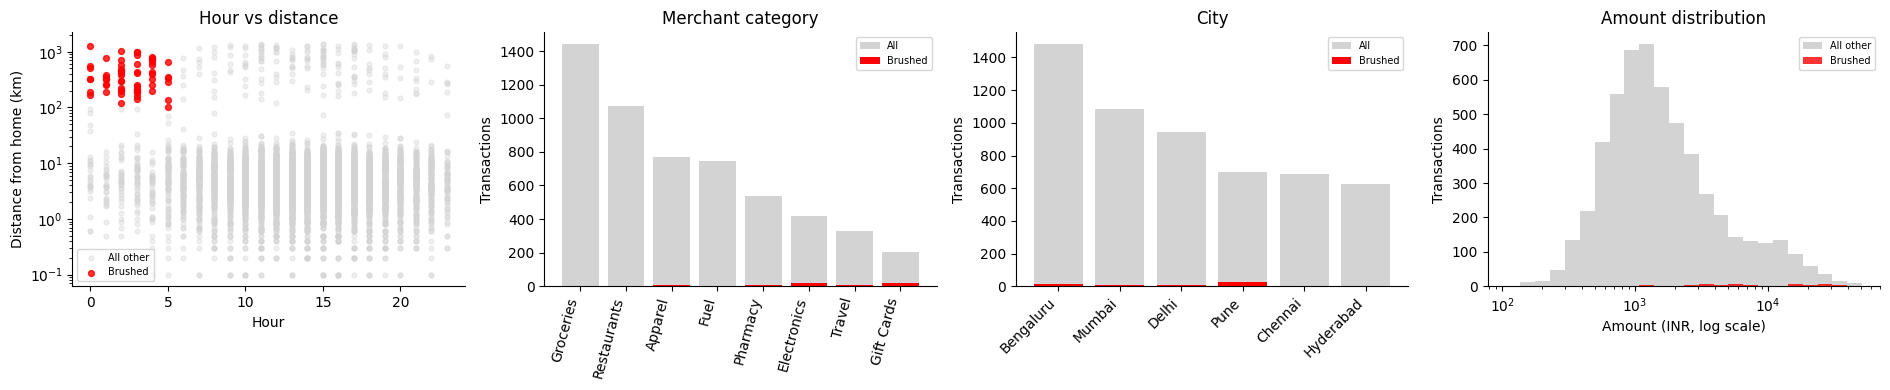

Brushed transactions: 61
Fraud rate inside brush: 86.9%
Overall fraud rate: 2.2%
Share of all confirmed fraud captured: 44.2%


In [3]:
# TODO 1: Brush = night-time and more than 100 km from home.
brush = tx["night"] & (tx["distance_from_home_km"] > 100)

fig, axes = plt.subplots(1, 4, figsize=(19, 4))

# TODO 2a: Hour vs. distance scatter (log y), with linked highlighting.
axes[0].scatter(tx.loc[~brush, "hour"], tx.loc[~brush, "distance_from_home_km"],
                color="lightgrey", alpha=.35, s=12, label="All other")
axes[0].scatter(tx.loc[brush, "hour"], tx.loc[brush, "distance_from_home_km"],
                color="red", alpha=.8, s=18, label="Brushed")
axes[0].set_yscale("log")
axes[0].set_xlabel("Hour")
axes[0].set_ylabel("Distance from home (km)")
axes[0].set_title("Hour vs distance")
axes[0].legend(fontsize=7)

# TODO 2b: Merchant category counts.
cat_all = tx["merchant_category"].value_counts()
cat_brush = tx.loc[brush, "merchant_category"].value_counts().reindex(cat_all.index, fill_value=0)
x = np.arange(len(cat_all))
axes[1].bar(x, cat_all.values, color="lightgrey", label="All")
axes[1].bar(x, cat_brush.values, color="red", label="Brushed")
axes[1].set_xticks(x, cat_all.index, rotation=75, ha="right")
axes[1].set_title("Merchant category")
axes[1].set_ylabel("Transactions")
axes[1].legend(fontsize=7)

# TODO 2c: City counts.
city_all = tx["city"].value_counts()
city_brush = tx.loc[brush, "city"].value_counts().reindex(city_all.index, fill_value=0)
x = np.arange(len(city_all))
axes[2].bar(x, city_all.values, color="lightgrey", label="All")
axes[2].bar(x, city_brush.values, color="red", label="Brushed")
axes[2].set_xticks(x, city_all.index, rotation=45, ha="right")
axes[2].set_title("City")
axes[2].set_ylabel("Transactions")
axes[2].legend(fontsize=7)

# TODO 2d: Amount histogram on a log10 x-axis.
bins = np.logspace(np.log10(tx.amount_inr.min()), np.log10(tx.amount_inr.max()), 25)
axes[3].hist(tx.loc[~brush, "amount_inr"], bins=bins, color="lightgrey", label="All other")
axes[3].hist(tx.loc[brush, "amount_inr"], bins=bins, color="red", alpha=.8, label="Brushed")
axes[3].set_xscale("log")
axes[3].set_xlabel("Amount (INR, log scale)")
axes[3].set_ylabel("Transactions")
axes[3].set_title("Amount distribution")
axes[3].legend(fontsize=7)

plt.tight_layout(); plt.show()

# TODO 3: Brush size, precision-like fraud rate, and capture of all fraud.
brushed_n = int(brush.sum())
fraud_inside = int(tx.loc[brush, "is_fraud"].sum())
fraud_total = int(tx["is_fraud"].sum())
print(f"Brushed transactions: {brushed_n:,}")
print(f"Fraud rate inside brush: {fraud_inside/brushed_n:.1%}")
print(f"Overall fraud rate: {fraud_total/len(tx):.1%}")
print(f"Share of all confirmed fraud captured: {fraud_inside/fraud_total:.1%}")


**Your answer:** The brush contains 61 transactions and 53 are confirmed fraud, so its fraud rate is 86.9% (compared with 2.2% overall). However, it captures only 44.2% of all confirmed fraud; 67 fraud cases remain outside the brush. Investigators should therefore use this rule as a high-risk prioritisation signal, not as the only fraud rule. The **city linked view** hints at the rest: confirmed fraud outside the brush is still distributed across Pune (27), Bengaluru (10), Mumbai (9), Hyderabad (8), Chennai (7) and Delhi (6), so a night-and-distance rule misses cases across cities.

## Task 3 — Will the Slider Still Feel Instant? (Request #3)

**Real-world usage:** Interactive tools are sized against latency budgets before they're built.

**Why this technique:** **Dynamic queries** need feedback within ~0.1 s (Slides 15–16).

**TODO:**
1. Build a 1-million-row table by repeating `tx`, and measure the time of the filter
   `(detector_score >= 0.6) & (amount_inr > 3000)` (take the best of 5 runs).
2. Compute the per-item cost (µs) and the maximum number of rows filterable within 0.1 s on this machine.
3. Estimate the response time for 50,000,000 rows and the % of rows that would need to be skipped (pre-indexed /
   pre-aggregated) to meet the 0.1 s budget.

In [4]:
big = pd.concat([tx] * 182, ignore_index=True)

# TODO 1: Best of five timings for the requested filter.
filter_expr = (big["detector_score"] >= 0.6) & (big["amount_inr"] > 3000)
timings = []
for _ in range(5):
    start = time.perf_counter()
    filtered = big.loc[filter_expr]
    timings.append(time.perf_counter() - start)
best_s = min(timings)

# TODO 2: Linear per-row estimate and 0.1-second capacity.
per_item_us = best_s / len(big) * 1_000_000
max_rows = 0.1 / (best_s / len(big))

# TODO 3: Extrapolate to 50 million rows and estimate required reduction.
t_50m = 50_000_000 * (best_s / len(big))
skip_pct = max(0, (1 - 0.1 / t_50m) * 100)

print(f"{len(big):,} rows in {best_s*1000:.1f} ms -> {per_item_us:.4f} us/row -> max {max_rows:,.0f} rows in 0.1 s")
print(f"50M rows -> {t_50m:.2f} s; must skip {skip_pct:.1f}% of rows to stay under 0.1 s")
print("Five measured times (ms):", [round(t*1000, 3) for t in timings])


1,004,640 rows in 12.0 ms -> 0.0120 us/row -> max 8,349,642 rows in 0.1 s
50M rows -> 0.60 s; must skip 83.3% of rows to stay under 0.1 s
Five measured times (ms): [16.937, 17.114, 15.932, 12.032, 13.047]


**Your answer:** One reduce technique is **sampling** (for example, use a representative subset or a pre-aggregated overview while the user moves the slider). It reduces the amount of data processed and can keep feedback responsive. The trade-off is that the analyst may miss rare fraud cases or small clusters, and the displayed counts/rates may be approximate rather than exact. The full-resolution data should remain available for drill-down and final investigation.

## Task 4 — Steer the Threshold to the Team's Capacity (Request #4)

**Real-world usage:** Alert thresholds are set against investigator capacity, not just statistical optimality.

**Why this technique:** **Human-in-the-loop** steering of a model parameter (Slide 37) evaluated with **precision, recall,
F1** (Slides 40–41).

**TODO:**
1. For thresholds 0.05, 0.10, …, 0.95 compute alerts (flagged count), TP, FP, FN, precision, recall and F1.
2. Find the threshold with the **highest recall** among those producing **≤ 150 alerts**. Also find the best-F1 threshold.
3. Plot the precision–recall curve and mark the current threshold (0.5), the capacity-constrained choice and the best-F1
   choice.
4. Print a one-line recommendation.

,threshold,alerts,TP,FP,FN,precision,recall,F1
0,0.05,2012,114,1898,6,0.056660,0.950000,0.106942
1,0.10,1167,111,1056,9,0.095116,0.925000,0.172494
2,0.15,786,110,676,10,0.139949,0.916667,0.242826
3,0.20,596,106,490,14,0.177852,0.883333,0.296089
4,0.25,471,105,366,15,0.222930,0.875000,0.355330
5,0.30,401,104,297,16,0.259352,0.866667,0.399232
6,0.35,355,104,251,16,0.292958,0.866667,0.437895
7,0.40,319,104,215,16,0.326019,0.866667,0.473804
8,0.45,283,104,179,16,0.367491,0.866667,0.516129
9,0.50,260,101,159,19,0.388462,0.841667,0.531579


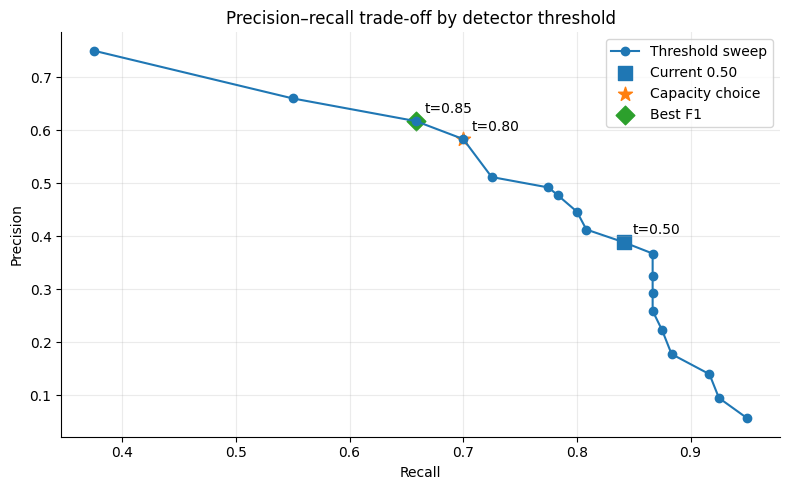

Recommendation: use threshold 0.80 (144 alerts, precision 58.3%, recall 70.0%, F1 0.636); it is the highest-recall tested threshold within the 150-alert monthly capacity. Best F1 is 0.85 (128 alerts).


In [5]:
rows = []
# TODO 1: Confusion-matrix counts and metrics at each threshold.
y = tx["is_fraud"].to_numpy()
for threshold in np.round(np.arange(0.05, 1.00, 0.05), 2):
    pred = (tx["detector_score"].to_numpy() >= threshold)
    tp = int(((pred) & (y == 1)).sum())
    fp = int(((pred) & (y == 0)).sum())
    fn = int(((~pred) & (y == 1)).sum())
    precision = tp / (tp + fp) if tp + fp else 0.0
    recall = tp / (tp + fn) if tp + fn else 0.0
    f1 = 2 * precision * recall / (precision + recall) if precision + recall else 0.0
    rows.append({"threshold": threshold, "alerts": int(pred.sum()), "TP": tp, "FP": fp,
                 "FN": fn, "precision": precision, "recall": recall, "F1": f1})

pr = pd.DataFrame(rows)
display(pr)

# TODO 2: Highest recall within the 150-alert capacity and best F1 overall.
eligible = pr[pr["alerts"] <= 150]
capacity_choice = eligible.sort_values(["recall", "threshold"], ascending=[False, True]).iloc[0]
best_f1 = pr.loc[pr["F1"].idxmax()]

# TODO 3: Precision-recall curve with the three requested operating points.
fig, ax = plt.subplots(figsize=(8, 5))
ax.plot(pr["recall"], pr["precision"], marker="o", label="Threshold sweep")
for _, r in pr[pr["threshold"].isin([0.50, capacity_choice["threshold"], best_f1["threshold"]])].iterrows():
    ax.annotate(f't={r["threshold"]:.2f}', (r["recall"], r["precision"]),
                xytext=(6, 6), textcoords="offset points")
ax.scatter([pr.loc[pr.threshold.eq(0.50), "recall"].iloc[0]],
           [pr.loc[pr.threshold.eq(0.50), "precision"].iloc[0]], s=90, marker="s", label="Current 0.50")
ax.scatter([capacity_choice["recall"]], [capacity_choice["precision"]],
           s=110, marker="*", label="Capacity choice")
ax.scatter([best_f1["recall"]], [best_f1["precision"]],
           s=90, marker="D", label="Best F1")
ax.set_xlabel("Recall")
ax.set_ylabel("Precision")
ax.set_title("Precision–recall trade-off by detector threshold")
ax.grid(alpha=.25)
ax.legend()
plt.tight_layout(); plt.show()

# TODO 4: Recommendation.
print(f"Recommendation: use threshold {capacity_choice['threshold']:.2f} "
      f"({int(capacity_choice['alerts'])} alerts, precision {capacity_choice['precision']:.1%}, "
      f"recall {capacity_choice['recall']:.1%}, F1 {capacity_choice['F1']:.3f}); "
      f"it is the highest-recall tested threshold within the 150-alert monthly capacity. "
      f"Best F1 is {best_f1['threshold']:.2f} ({int(best_f1['alerts'])} alerts).")


**Your answer:** The **Head of Fraud Ops** should make the final call, using the model metrics as evidence. The model can identify the precision–recall trade-off, but it does not know the team's actual staffing, investigation time, business risk tolerance or the cost of missed fraud. Visual analytics keeps a human in the loop because people must steer the threshold, inspect the consequences and balance competing operational goals rather than blindly accept a mathematically optimal score (Slides 35–37).

## Task 5 — An Interactive Tool for the Investigators (Request #5)

**Real-world usage:** Investigators triage flagged cases themselves with zoom, filter and hover-for-details.

**Why this technique:** **Details-on-demand / tooltips** (Slides 22–23), **dynamic queries** (Slide 15) and **drill-down**
(Slide 24) — Shneiderman's mantra as an actual tool.

**TODO:**
1. Interactive scatter (plotly) of all transactions with `detector_score >= 0.3`: x = timestamp, y = amount (log),
   colour = `label`, with a tooltip showing txn_id, customer, city, category, distance and score. Set `dragmode="select"`.
2. Interactive **sunburst** for drill-down: city → merchant category, sized by transaction count, coloured by fraud rate.

In [6]:
# TODO 1: Interactive scatter of all transactions with detector score >= 0.3.
flagged = tx.loc[tx["detector_score"] >= 0.3].copy()
scatter = px.scatter(
    flagged, x="timestamp", y="amount_inr", color="label",
    log_y=True, hover_data={
        "txn_id": True, "customer_id": True, "city": True,
        "merchant_category": True, "distance_from_home_km": ":.1f",
        "detector_score": ":.3f", "timestamp": True, "amount_inr": ":.2f"
    },
    title="Flagged transactions (detector score ≥ 0.3)"
)
scatter.update_layout(dragmode="select", xaxis_title="Timestamp",
                      yaxis_title="Amount (INR, log scale)")
scatter.show()

# TODO 2: Sunburst drill-down: city -> merchant category.
sun = (flagged.groupby(["city", "merchant_category"], as_index=False)
       .agg(transaction_count=("txn_id", "size"), fraud_rate=("is_fraud", "mean")))
sunburst = px.sunburst(
    sun, path=["city", "merchant_category"], values="transaction_count",
    color="fraud_rate", color_continuous_scale="Reds",
    range_color=(0, 1), hover_data={"transaction_count": True, "fraud_rate": ":.1%"},
    title="Flagged transactions: drill down from city to merchant category"
)
sunburst.show()


**Your answer:** A tooltip gives detail for only the item currently under the pointer. To inspect 400 flagged cases one by one would require hundreds of hover actions, making comparisons, clusters and outliers difficult to notice. The **overview heatmap from Task 1** fixes the overview problem by showing the distribution of confirmed fraud across city and day at once; the linked views in Task 2 also help compare a selected subset across dimensions. Tooltips should be used after the analyst has narrowed the view to cases of interest (details-on-demand).

## Task 6 — Prove or Kill the "Fraud Ring" Hypothesis (Request #6)

**Real-world usage:** Before escalating to law enforcement, the team must rule out simpler explanations.

**Why this technique:** **Hypothesis testing** with visual + statistical confirmation and an explicit **counter-example
search** to guard against confirmation bias (Slides 42–43).

**TODO:**
1. State the hypothesis precisely using what you found in Task 1 (city and day range).
2. Compute the fraud rate inside vs. outside that city–day window and a chi-square p-value
   (`scipy.stats.chi2_contingency` on `pd.crosstab(in_window, tx.is_fraud)`).
3. Counter-example searches: fraud rate for (a) the same city on other days, (b) other cities on the same days.
4. Visual confirmation: a bar chart of the four groups (window / same city other days / other cities same days / rest).
5. Print your verdict.

Hypothesis: fraud is concentrated in Pune during days 18–20.
Window: 107 transactions; 40 fraud; rate 37.4%
Outside window: 5413 transactions; rate 1.5%
Chi-square=619.29, df=1, p-value=1.065e-136
Expected frequencies: [[5.29532609e+03 1.17673913e+02]
 [1.04673913e+02 2.32608696e+00]]


,group,transactions,fraud,fraud_rate
0,"Pune, days 18–20",107,40,0.373832
1,"Pune, other days",593,11,0.018550
2,"Other cities, days 18–20",457,2,0.004376
3,Rest,4363,67,0.015356


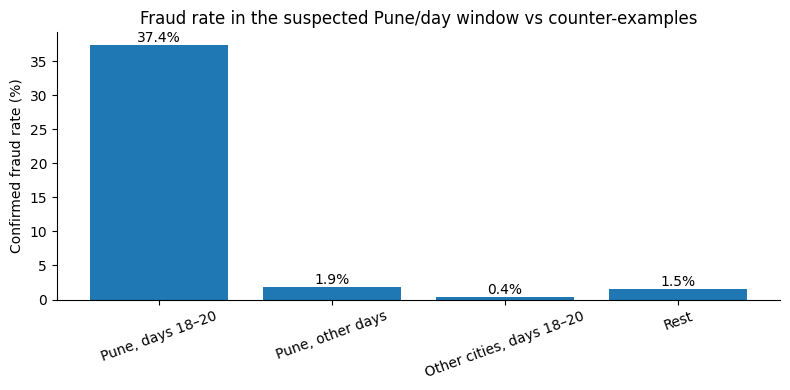

Verdict: the data strongly supports a localized Pune/day 18–20 fraud spike (37.4% vs 1.5%; chi-square p=1.06e-136). The counter-examples are much lower (Pune other days and other cities on those days), so the pattern is not explained by city alone or dates alone. This supports investigating a localized event, but does not prove a coordinated fraud ring; shared customers, merchants, or other operational causes should be checked.


In [7]:
from scipy.stats import chi2_contingency

# TODO 1: Hypothesis based on the strongest Task 1 cluster:
# H1: confirmed fraud is unusually concentrated in Pune on days 18–20.
in_window = tx["city"].eq("Pune") & tx["day"].between(18, 20)

# TODO 2: Compare rates and run the requested chi-square test.
same_city_other = tx["city"].eq("Pune") & ~tx["day"].between(18, 20)
other_cities_same = ~tx["city"].eq("Pune") & tx["day"].between(18, 20)
rest = ~(in_window | same_city_other | other_cities_same)
chi2, p_value, dof, expected = chi2_contingency(pd.crosstab(in_window, tx["is_fraud"]))
print("Hypothesis: fraud is concentrated in Pune during days 18–20.")
print(f"Window: {int(in_window.sum())} transactions; {int(tx.loc[in_window, 'is_fraud'].sum())} fraud; "
      f"rate {tx.loc[in_window, 'is_fraud'].mean():.1%}")
print(f"Outside window: {int((~in_window).sum())} transactions; "
      f"rate {tx.loc[~in_window, 'is_fraud'].mean():.1%}")
print(f"Chi-square={chi2:.2f}, df={dof}, p-value={p_value:.3e}")
print("Expected frequencies:", expected)

# TODO 3: Explicit counter-example searches.
group_masks = {
    "Pune, days 18–20": in_window,
    "Pune, other days": same_city_other,
    "Other cities, days 18–20": other_cities_same,
    "Rest": rest
}
summary = []
for name, mask in group_masks.items():
    n = int(mask.sum())
    fraud_n = int(tx.loc[mask, "is_fraud"].sum())
    summary.append({"group": name, "transactions": n, "fraud": fraud_n,
                    "fraud_rate": fraud_n / n if n else 0})
group_summary = pd.DataFrame(summary)
display(group_summary)

# TODO 4: Visual confirmation of the four groups.
fig, ax = plt.subplots(figsize=(8, 4))
bars = ax.bar(group_summary["group"], group_summary["fraud_rate"] * 100)
ax.set_ylabel("Confirmed fraud rate (%)")
ax.set_title("Fraud rate in the suspected Pune/day window vs counter-examples")
ax.tick_params(axis="x", rotation=20)
for bar, rate in zip(bars, group_summary["fraud_rate"]):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height(),
            f"{rate:.1%}", ha="center", va="bottom")
plt.tight_layout(); plt.show()

# TODO 5: Verdict with appropriate caution about association vs causation.
window_rate = tx.loc[in_window, "is_fraud"].mean()
outside_rate = tx.loc[~in_window, "is_fraud"].mean()
print("Verdict: the data strongly supports a localized Pune/day 18–20 fraud spike "
      f"({window_rate:.1%} vs {outside_rate:.1%}; chi-square p={p_value:.2e}). "
      "The counter-examples are much lower (Pune other days and other cities on those days), "
      "so the pattern is not explained by city alone or dates alone. This supports investigating "
      "a localized event, but does not prove a coordinated fraud ring; shared customers, merchants, "
      "or other operational causes should be checked.")


**Your answer:** The most important counter-example is **other cities on days 18–20**: if that group had shown a similarly high fraud rate, the spike would look like a date-wide event (for example, a system outage, promotion or detector/configuration issue) rather than a Pune-specific ring. The **Pune on other days** search is also important: if it had stayed equally high, the alternative would be a persistent Pune-specific risk or customer/merchant mix, not a short-lived ring. In the actual data both rates are low, which makes the Pune-and-date interaction more unusual, but still does not prove coordination.

## Final note to the Head of Fraud Ops

Last month PayKart processed **5,520 transactions** and investigators confirmed **120 fraud cases (2.17%)**, with a pronounced cluster of **40 fraud cases among 107 transactions in Pune on days 18–20**. I recommend a threshold of **0.80**: it produces **144 alerts**, within the 150-alert capacity, with **58.3% precision and 70.0% recall**; the best-F1 threshold (0.85) is slightly more selective but has lower recall, so the Head of Fraud Ops should approve the trade-off based on staffing and the cost of missed fraud. Build the **interactive flagged-transaction scatter first**, because investigators can select/zoom through cases and use details-on-demand tooltips, then drill down by city and merchant category with the sunburst; retain an overview heatmap for the whole-month pattern. The 50-million-row timing estimate shows that a full scan would exceed the 0.1-second dynamic-query budget, so the production tool should use indexing/pre-aggregation and/or representative sampling for immediate feedback while preserving exact drill-down. Add a **human feedback loop**: investigators should label reviewed alerts and false positives/negatives, feed those confirmed outcomes back into the training/evaluation dataset, and periodically retrain and recalibrate the detector with the team's review-capacity constraints.